# ENTROPY
### Predicting the hidden cost of sending money to Africa

```
root@entropy:~# infer --target total_cost_pct --corridor *>AFRICA
```

**Mission.** Make financial infrastructure in Africa fairer and cheaper: transparent, low-cost rails for remittances, digital identity and peer-to-peer commerce.

**Problem.** Sub-Saharan Africa is the most expensive region in the world to send money to. A $200 transfer loses about 8% on average, while the UN target (SDG 10.c) is **3%**. Much of that cost is not the visible fee but the **FX margin** hidden inside the exchange rate. That makes the pricing *high-entropy*: the same transfer can cost 1% or 30% depending on the corridor and the service.

**Use case: who uses the prediction, and for what.**

| User | What they do with the predicted cost |
|---|---|
| **Remittance / blockchain fintech teams** (e.g. a stablecoin remittance rail) | Benchmark the all-in price incumbents charge for a given corridor and service profile, i.e. the number their product has to beat. |
| **Central-bank & regulator analysts** | Flag corridors and service types whose expected cost sits far above the 3% SDG target. |

**Target.** `total_cost_pct`: the all-in cost (fee + FX margin) of sending the equivalent of **USD 200**, as a % of the amount sent. It is continuous, so this is a regression problem.

| Dataset card | |
|---|---|
| Source | World Bank, **Remittance Prices Worldwide** (RPW): [datacatalog.worldbank.org/search/dataset/0037898](https://datacatalog.worldbank.org/search/dataset/0037898/remittance-prices-worldwide) |
| Licence | CC BY 4.0 (attribution: *The World Bank, Remittance Prices Worldwide, remittanceprices.worldbank.org*) |
| Slice used | Every price quote sent **into an African country**, Q2 2016 to Q3 2025 |
| Collection | Mystery-shopping of real remittance providers each quarter (not synthetic) |

## 0. Setup

In [1]:
import tempfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50, "display.width", 160, "display.max_colwidth", 120)

# ENTROPY plot theme: terminal-dark surface; series colours validated for contrast and colour-blind separation.
SURFACE, INK, MUTED, GRID = "#0B0F0C", "#D7E0D9", "#8A968D", "#1C241F"
GREEN, BLUE, AMBER, ROSE = "#22B05F", "#3B9BE0", "#C27E00", "#DC4C7C"
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
MONO = next(f for f in ["JetBrains Mono", "Consolas", "DejaVu Sans Mono"] if f in installed_fonts)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.axisbelow": True, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.family": "monospace", "font.monospace": [MONO],
    "figure.dpi": 110,
})
SDG_TARGET = 3.0  # SDG 10.c: remittance cost below 3%

## 1. Load the data

The repo ships the Africa slice as a compressed CSV. If it is missing, the cell rebuilds it from the World Bank's official workbook (48 MB) with a single filter: *destination country is one of the 54 African states*.

In [2]:
DATA_PATH = Path("data/rpw_africa_2016q2_2025q3.csv.gz")
RPW_URL = ("https://datacatalogfiles.worldbank.org/ddh-published/0037898/DR0095523/"
           "rpw_dataset_2011_2025_q3.xlsx")
AFRICA_ISO3 = set(
    "DZA AGO BEN BWA BFA BDI CPV CMR CAF TCD COM COD COG CIV DJI EGY GNQ ERI SWZ ETH GAB GMB GHA GIN "
    "GNB KEN LSO LBR LBY MDG MWI MLI MRT MUS MAR MOZ NAM NER NGA RWA STP SEN SYC SLE SOM ZAF SSD SDN "
    "TZA TGO TUN UGA ZMB ZWE".split()
)

if not DATA_PATH.exists():
    request = urllib.request.Request(RPW_URL, headers={"User-Agent": "Mozilla/5.0 (entropy-notebook)"})
    with tempfile.TemporaryDirectory() as tmp:
        workbook = Path(tmp) / "rpw.xlsx"
        workbook.write_bytes(urllib.request.urlopen(request, timeout=300).read())
        world = pd.read_excel(workbook, sheet_name="Dataset (from Q2 2016)")
    DATA_PATH.parent.mkdir(exist_ok=True)
    world[world["destination_code"].isin(AFRICA_ISO3)].to_csv(DATA_PATH, index=False)

raw = pd.read_csv(DATA_PATH, low_memory=False)
numeric_cols = raw.select_dtypes("number").columns
print(f"{len(raw):,} rows x {raw.shape[1]} columns "
      f"({len(numeric_cols)} numeric, {raw.shape[1] - len(numeric_cols)} categorical/text)")
print(f"{raw['destination_code'].nunique()} African destination countries | "
      f"{raw['source_code'].nunique()} sending countries | {raw['firm'].nunique()} providers | "
      f"{raw['period'].nunique()} quarters ({raw['period'].min()} to {raw['period'].max()})")
raw.head(3)

52,892 rows x 47 columns (15 numeric, 32 categorical/text)
38 African destination countries | 29 sending countries | 247 providers | 37 quarters (2016_2Q to 2025_3Q)


,id,period,source_code,source_name,source_region,source_income,source_lending,source_G8G20,destination_code,destination_name,destination_region,destination_income,destination_lending,destination_G8G20,firm,firm_type,payment instrument,access point,speed actual,cc1 lcu amount,cc1 denomination amount,cc1 lcu code,cc1 lcu fee,cc1 lcu fx rate,cc1 fx margin,cc1 total cost %,cc2 lcu amount,cc2 denomination amount,cc2 lcu code,cc2 lcu fee,cc2 lcu fx rate,cc2 fx margin,cc2 total cost %,inter lcu bank fx,transparent,Standard Note,note2,receiving network coverage,pickup location,pickup method,date,corridor,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46
0,620160001,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,Sub-Saharan Africa,Upper middle income,IBRD,..,MoneyGram,Money Transfer Operator,Cash,Agent,Less than one hour,33000.0,200.0,AOA,2900.0,0.084,7.49,16.28,83000.0,500.0,AOA,5700.0,0.084,7.49,14.36,0.0908,yes,NaN,NaN,High,Agent,Cash,11/May/2016,AGONAM,NaN,NaN,NaN,NaN,NaN
1,620160002,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,Sub-Saharan Africa,Upper middle income,IBRD,..,Real Transfer,Money Transfer Operator,"Bank account transfer,Cash",Agent,Same day,33000.0,200.0,AOA,3300.0,0.087,4.19,14.19,83000.0,500.0,AOA,6300.0,0.087,4.19,11.78,0.0908,yes,NaN,NaN,High,Agent,Cash,11/May/2016,AGONAM,NaN,NaN,NaN,NaN,NaN
2,620160003,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,Sub-Saharan Africa,Upper middle income,IBRD,..,Standard Bank,Bank,Bank account transfer,Bank branch,Next day,33000.0,200.0,AOA,9075.0,1.000,0.00,27.50,83000.0,500.0,AOA,9075.0,1.000,0.00,10.93,1.0000,no,This RSP is not transparent: the exchange rate applied to the transaction was not disclosed. The 0% in the exchange ...,NaN,Low,NaN,Bank account,11/May/2016,AGONAM,NaN,NaN,NaN,NaN,NaN


## 2. Clean the target

`cc1 total cost %` is the target. A *negative* cost would mean the provider paid the sender to transact, and costs above **40%** of the amount sent sit beyond the 99.5th percentile. Both are recording errors (wrong amount or currency keyed in), so those rows are removed rather than allowed to dominate a squared-error loss.

In [3]:
TARGET = "total_cost_pct"
MAX_PLAUSIBLE_COST = 40.0

audit = {"raw quotes": len(raw)}
df = raw.drop_duplicates(subset=raw.columns.drop("id"))
audit["exact duplicate quotes removed"] = len(df)
df = df.assign(**{TARGET: pd.to_numeric(df["cc1 total cost %"], errors="coerce")}).dropna(subset=[TARGET])
audit["missing target removed"] = len(df)
df = df[df[TARGET].between(0, MAX_PLAUSIBLE_COST)]
audit[f"cost outside 0-{MAX_PLAUSIBLE_COST:.0f}% removed"] = len(df)
pd.Series(audit, name="rows remaining").to_frame()

,rows remaining
raw quotes,52892
exact duplicate quotes removed,52886
missing target removed,52885
cost outside 0-40% removed,51994


## 3. Feature engineering

### 3.1 Columns dropped, and why

| Dropped column(s) | Reason |
|---|---|
| `cc1 lcu fee`, `cc1 fx margin`, `cc1 lcu fx rate`, `inter lcu bank fx`, `cc1 lcu amount` | **Target leakage.** The target *is* fee/amount + FX margin, so a model given these would copy the answer rather than learn it. They are also unknown until a quote has already been made, so a user could not supply them (proof in the next cell). |
| every `cc2 …` column | The same quote priced for USD 500: a second version of the target, so also leakage. |
| `cc1 denomination amount` | Constant (always 200), so it carries no information. |
| `cc1 lcu code` | Sending currency is fully determined by the sending country. |
| `source_name/region/income/lending/G8G20`, `destination_…` equivalents, `corridor` | Fully determined by the country codes we keep, so they are redundant and add collinearity. |
| `firm` | 247 brand names: an identifier, not a service characteristic. ENTROPY benchmarks *service profiles*, so it must work for a brand-new provider. |
| `id`, `date`, `Standard Note`, `note2`, `Unnamed: 42-46`, `pickup location` | Row IDs, free-text notes, empty spreadsheet columns, and a field that is mostly blank and duplicated by `pickup method`. |
| `period` | Re-expressed as numeric `year` and `quarter`. |

In [4]:
leaky = df[["cc1 fx margin", "cc2 total cost %"]].apply(pd.to_numeric, errors="coerce")
leaky = leaky.assign(**{"fee as % of amount": pd.to_numeric(df["cc1 lcu fee"], errors="coerce")
                        / pd.to_numeric(df["cc1 lcu amount"], errors="coerce") * 100})
leaky.corrwith(df[TARGET]).round(3).rename("correlation with target").to_frame()

,correlation with target
cc1 fx margin,0.442
cc2 total cost %,0.872
fee as % of amount,0.867


### 3.2 Building the candidate inputs

Several raw fields hold comma-separated *lists* (e.g. `"Bank account transfer,Debit/credit card"`). Each token is mapped to one canonical level. A quote offering several distinct levels becomes `MULTI`. Free-text speed becomes a number of hours, and the `period` string becomes `year` + `quarter`. Rare tokens with no stable meaning (24 quotes paid out via ATM or debit card) are dropped, so the API can reject them instead of guessing.

In [5]:
SPEED_HOURS = {"Less than one hour": 1, "Same day": 12, "Next day": 24, "2 days": 48,
               "3-5 days": 96, "6 days or more": 144}
FIRM_TYPE = {"bank": "BANK", "money transfer operator": "MTO", "mobile operator": "MOBILE_OPERATOR",
             "post office": "POST", "non-bank fi": "NON_BANK_FI"}
PAYMENT = {"cash": "CASH", "bank account transfer": "BANK_ACCOUNT", "debit card": "CARD", "credit card": "CARD",
           "debit/credit card": "CARD", "prepaid card": "CARD", "mobile money": "MOBILE_MONEY"}
ACCESS = {"agent": "AGENT", "internet": "ONLINE", "bank branch": "BRANCH", "call center": "CALL_CENTER",
          "post office branch": "POST_OFFICE", "post office": "POST_OFFICE", "mobile phone": "MOBILE_APP"}
PICKUP = {"cash": "CASH", "bank account": "BANK_ACCOUNT", "own/partner bank account": "BANK_ACCOUNT",
          "bank account (same/partner bank)": "BANK_ACCOUNT", "mobile wallet": "MOBILE_WALLET"}


def canonical(value, vocabulary, sep=","):
    # One canonical level per quote; several distinct levels -> MULTI; any unknown token -> None (row dropped).
    levels = {vocabulary.get(token.strip().lower()) for token in str(value).split(sep)}
    if None in levels:
        return None
    return levels.pop() if len(levels) == 1 else "MULTI"


period = df["period"].str.extract(r"(?P<year>\d{4})_(?P<quarter>\d)Q").astype(int)
data = pd.DataFrame({
    "source_country": df["source_code"],
    "destination_country": df["destination_code"],
    "firm_type": df["firm_type"].map(lambda v: canonical(v, FIRM_TYPE, sep="/")),
    "payment_instrument": df["payment instrument"].map(lambda v: canonical(v, PAYMENT)),
    "access_point": df["access point"].map(lambda v: canonical(v, ACCESS)),
    "pickup_method": df["pickup method"].map(lambda v: canonical(v, PICKUP)),
    "network_coverage": df["receiving network coverage"].str.upper(),
    "transparent": df["transparent"].str.lower(),
    "speed_hours": df["speed actual"].map(SPEED_HOURS),
    "year": period["year"],
    "quarter": period["quarter"],
    TARGET: df[TARGET],
}).dropna().reset_index(drop=True)
data["speed_hours"] = data["speed_hours"].astype(int)

CATEGORICAL = ["source_country", "destination_country", "firm_type", "payment_instrument",
               "access_point", "pickup_method", "network_coverage", "transparent"]
NUMERIC_CANDIDATES = ["speed_hours", "year", "quarter"]
CANDIDATES = CATEGORICAL + NUMERIC_CANDIDATES

print(f"{len(data):,} clean quotes | {len(CANDIDATES)} candidate features "
      f"({len(CATEGORICAL)} categorical + {len(NUMERIC_CANDIDATES)} numeric)")
pd.DataFrame({"levels": data[CATEGORICAL].nunique(),
              "values": [sorted(data[c].unique()) if data[c].nunique() < 10 else "ISO3 codes"
                         for c in CATEGORICAL]})

51,970 clean quotes | 11 candidate features (8 categorical + 3 numeric)


,levels,values
source_country,29,ISO3 codes
destination_country,38,ISO3 codes
firm_type,6,"[BANK, MOBILE_OPERATOR, MTO, MULTI, NON_BANK_FI, POST]"
payment_instrument,5,"[BANK_ACCOUNT, CARD, CASH, MOBILE_MONEY, MULTI]"
access_point,7,"[AGENT, BRANCH, CALL_CENTER, MOBILE_APP, MULTI, ONLINE, POST_OFFICE]"
pickup_method,3,"[BANK_ACCOUNT, CASH, MOBILE_WALLET]"
network_coverage,3,"[HIGH, LOW, MEDIUM]"
transparent,2,"[no, yes]"


### 3.3 Hold out the newest quarter as "new data"

**Q3 2025** is the World Bank's most recent release. It is removed *now*, before any exploration or training, and saved later as the CSV uploaded to the API's `/retrain` endpoint. This simulates the real event "a new quarter of prices is published" with genuine data the model has never seen.

In [6]:
is_newest = (data["year"] == 2025) & (data["quarter"] == 3)
new_quarter = data[is_newest].reset_index(drop=True)
data = data[~is_newest].reset_index(drop=True)
print(f"modelling set: {len(data):,} quotes (2016 Q2 to 2025 Q1) | held-out new quarter: {len(new_quarter):,} quotes")

modelling set: 50,248 quotes (2016 Q2 to 2025 Q1) | held-out new quarter: 1,722 quotes


## 4. Explore

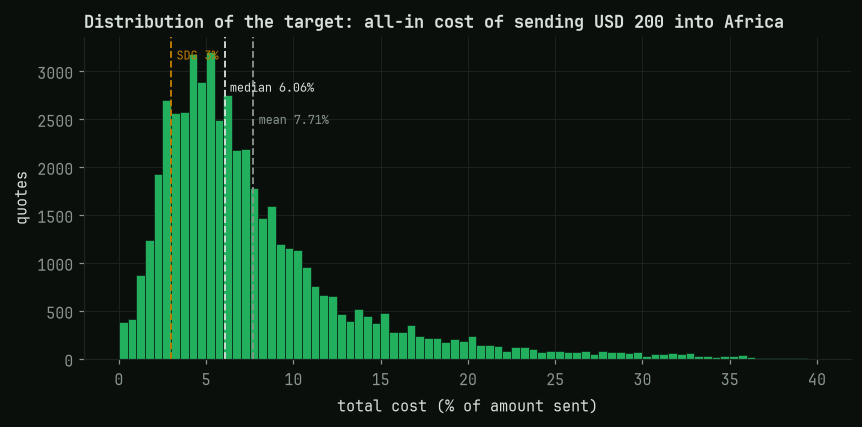

median 6.06% | mean 7.71% | skew 1.96 | 84% of quotes above the SDG target | 95th pct 19.9%


In [7]:
y = data[TARGET]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(y, bins=80, color=GREEN, edgecolor=SURFACE, linewidth=0.4)
for height, (value, label, color) in zip([0.93, 0.83, 0.73], [
        (SDG_TARGET, f"SDG {SDG_TARGET:.0f}%", AMBER),
        (y.median(), f"median {y.median():.2f}%", INK),
        (y.mean(), f"mean {y.mean():.2f}%", MUTED)]):
    ax.axvline(value, color=color, linestyle="--", linewidth=1.2)
    ax.text(value + 0.3, ax.get_ylim()[1] * height, label, color=color, fontsize=8)
ax.set(title="Distribution of the target: all-in cost of sending USD 200 into Africa",
       xlabel="total cost (% of amount sent)", ylabel="quotes")
plt.show()
print(f"median {y.median():.2f}% | mean {y.mean():.2f}% | skew {y.skew():.2f} | "
      f"{(y > SDG_TARGET).mean():.0%} of quotes above the SDG target | 95th pct {y.quantile(.95):.1f}%")

**4.1 Target distribution.** **What it shows:** costs are right-skewed (skew 1.96), with a median of 6.06%, a mean of 7.71% and a long tail out to 40%. **84% of quotes are above the 3% SDG target.**
**Decision:** keep the target in plain percentage points, with no log transform, so both the test MSE and the API's answer are directly interpretable. Squared error punishes misses on the expensive tail hardest, which is why implausible >40% records were removed first, and why models that can isolate expensive segments should do best.

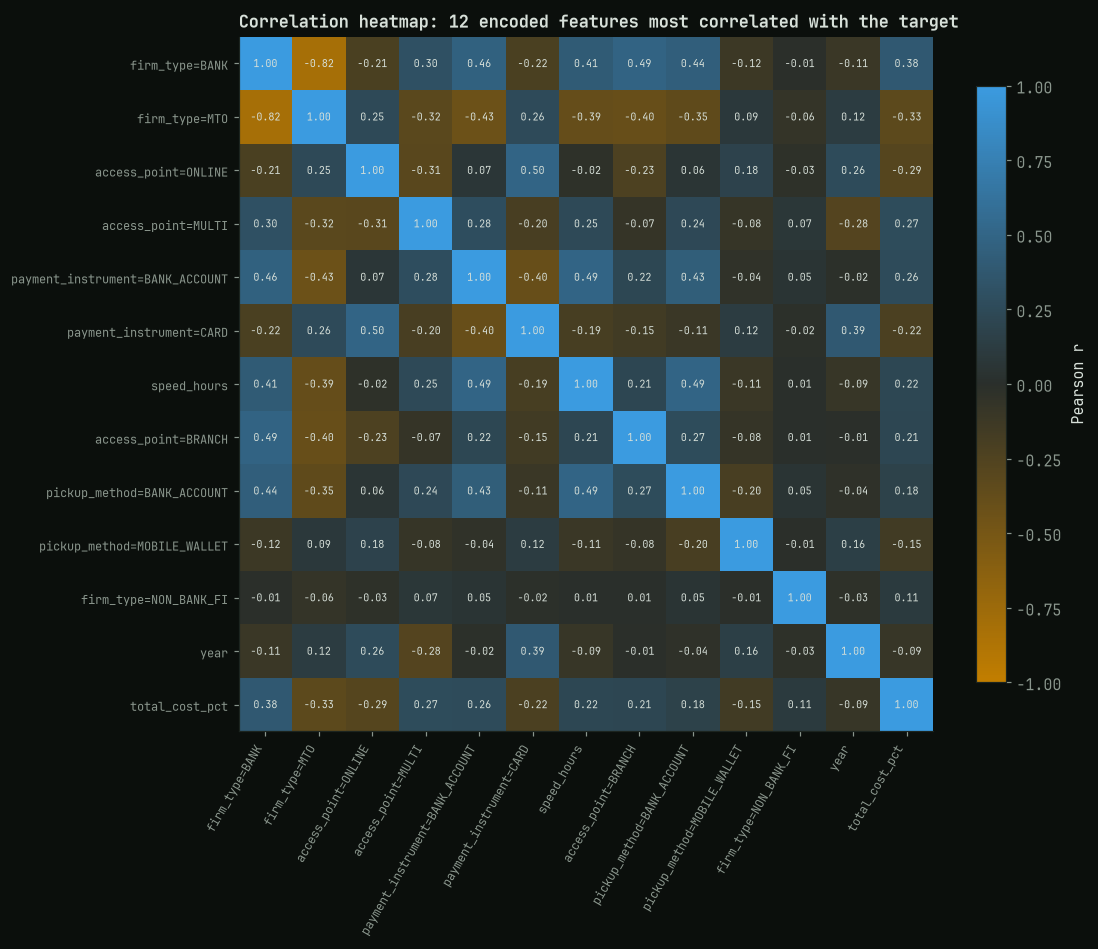

,r with target
firm_type=MTO,-0.334
access_point=ONLINE,-0.288
payment_instrument=CARD,-0.224
pickup_method=MOBILE_WALLET,-0.152
year,-0.092
firm_type=NON_BANK_FI,0.106
pickup_method=BANK_ACCOUNT,0.179
access_point=BRANCH,0.214
speed_hours,0.222
payment_instrument=BANK_ACCOUNT,0.258


In [8]:
encoded = pd.get_dummies(data[CATEGORICAL[2:]], prefix_sep="=", dtype=float).join(data[NUMERIC_CANDIDATES + [TARGET]])
top = encoded.corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(12).index
corr = encoded[list(top) + [TARGET]].corr()

diverging = LinearSegmentedColormap.from_list("entropy_div", [AMBER, "#2A2F2B", BLUE])
fig, ax = plt.subplots(figsize=(10, 8.2))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color=INK)
fig.colorbar(im, ax=ax, fraction=0.035, label="Pearson r")
ax.set_title("Correlation heatmap: 12 encoded features most correlated with the target")
plt.show()
corr[TARGET].drop(TARGET).sort_values().round(3).to_frame("r with target")

**4.2 Correlation heatmap.** **What it shows:** being a **bank** is the strongest single encoded signal (r = +0.38). Money-transfer operators (-0.33), online access (-0.29), card funding (-0.22) and mobile-wallet pickup (-0.15) all pull cost down, and `year` (-0.09) shows prices slowly falling. The inputs are also correlated with *each other* (BANK vs MTO -0.82, card vs online +0.50, speed vs bank-account funding +0.49).
**Decision:** no feature is strongly linear on its own (|r| <= 0.38), so the signal lives in *combinations*. Keep all inputs, regularise the gradient-descent model (`alpha`) against the collinearity, and expect tree models, which learn interactions, to beat the straight-line models.

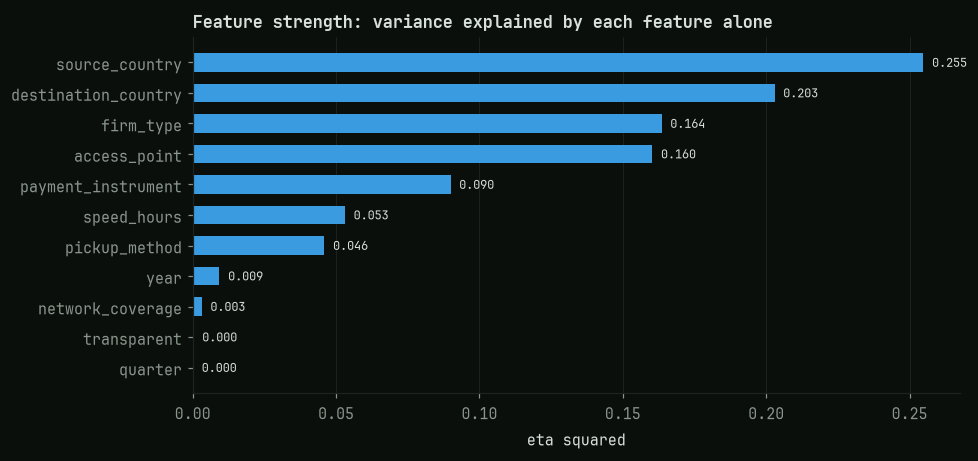

In [9]:
def correlation_ratio(groups, values):
    # eta^2: share of the target's variance explained by the feature's group means (works for categorical inputs).
    group_means = values.groupby(groups).transform("mean")
    return ((group_means - values.mean()) ** 2).sum() / ((values - values.mean()) ** 2).sum()


strength = pd.Series({f: correlation_ratio(data[f], y) for f in CANDIDATES}).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(strength.index, strength.values, color=BLUE, height=0.6)
for i, v in enumerate(strength.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8, color=INK)
ax.set(title="Feature strength: variance explained by each feature alone",
       xlabel="eta squared")
ax.grid(axis="y", visible=False)
plt.show()

**4.3 Feature strength.** **What it shows:** who sends and who receives matter most. Sending country alone explains **25.5%** of the variance and destination country **20.3%** (corridor competition, FX regimes, regulation), followed by provider type (16.4%) and access point (16.0%). These four are the features that matter most for the target.
**Decision:** `quarter` explains 0.000, so it is **dropped** (prices have no seasonality), leaving **10 inputs**. `transparent` also scores about 0 on its own but is **kept**: when a provider hides its exchange rate, the data records the FX margin as 0, so the target *understates* those quotes. The model needs this flag to read them correctly.

In [10]:
NUMERIC = ["speed_hours", "year"]  # 'quarter' dropped: eta squared = 0.000, so prices show no seasonality
FEATURES = CATEGORICAL + NUMERIC
print(f"final model inputs ({len(FEATURES)}): {FEATURES}")

final model inputs (10): ['source_country', 'destination_country', 'firm_type', 'payment_instrument', 'access_point', 'pickup_method', 'network_coverage', 'transparent', 'speed_hours', 'year']


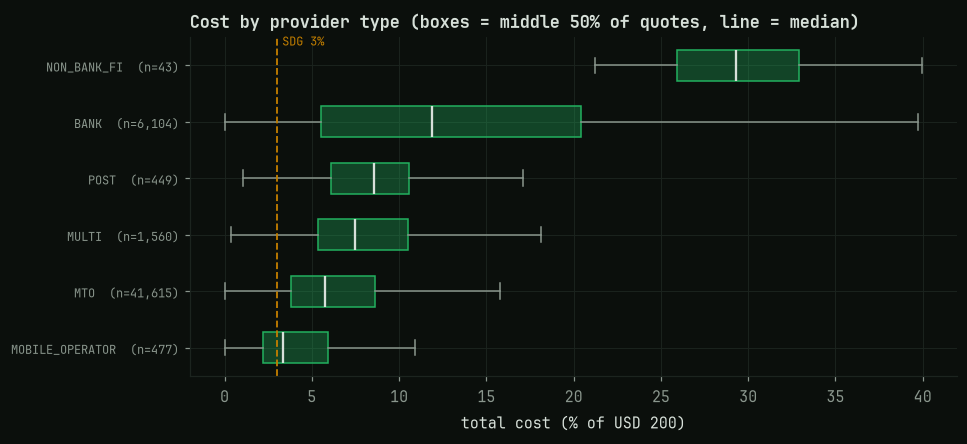

In [11]:
order = data.groupby("firm_type")[TARGET].median().sort_values().index
groups = [data.loc[data["firm_type"] == f, TARGET] for f in order]
fig, ax = plt.subplots(figsize=(9, 4))
box = ax.boxplot(groups, orientation="horizontal", showfliers=False, patch_artist=True, widths=0.55,
                 medianprops={"color": INK, "linewidth": 1.5}, whiskerprops={"color": MUTED},
                 capprops={"color": MUTED}, boxprops={"edgecolor": GREEN})
for patch in box["boxes"]:
    patch.set_facecolor(GREEN + "55")
ax.set_yticks(range(1, len(order) + 1), [f"{f}  (n={len(g):,})" for f, g in zip(order, groups)], fontsize=8)
ax.axvline(SDG_TARGET, color=AMBER, linestyle="--", linewidth=1.2)
ax.text(SDG_TARGET + 0.3, len(order) + 0.35, "SDG 3%", color=AMBER, fontsize=8)
ax.set(title="Cost by provider type (boxes = middle 50% of quotes, line = median)",
       xlabel="total cost (% of USD 200)")
plt.show()

**4.4 Cost by provider type.** **What it shows:** mobile operators are the only provider type whose median (about 3.3%) sits at the SDG target. Money-transfer operators dominate the market (41,615 quotes, median about 5.7%). Banks are both expensive (median about 12%) and extremely variable (the middle half of quotes spans about 5.5% to 20%).
**Decision:** provider type is a required input, and the huge spread *inside* BANK shows that one coefficient per type cannot explain cost. That is another reason to compare against tree models. It is also the mission insight: digital/mobile rails are already the cheapest, and that is the gap new rails must widen.

## 5. Encode, split and standardise

* **Encode:** `OneHotEncoder` turns each categorical column into 0/1 columns, and `handle_unknown="ignore"` means an unseen level becomes all-zeros instead of crashing. The 2 numeric columns (`speed_hours`, `year`) pass through unchanged.
* **Split:** 80% train / 20% test, with a fixed seed so every model is scored on exactly the same test rows.
* **Standardise:** `StandardScaler` puts every column at mean 0 and std 1, which SGD needs to converge. It is **fitted on the training set only**. The test set is transformed with the training means and standard deviations, so no test information leaks into training.

Both steps live in one scikit-learn `Pipeline`. Every model trained later reuses it, so the saved model carries its own preprocessing.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X, y = data[FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

preprocess = Pipeline([
    ("encode", ColumnTransformer(
        [("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
        remainder="passthrough")),
    ("scale", StandardScaler()),
])
X_train_ready = preprocess.fit_transform(X_train)   # learns categories, means and stds from TRAIN only
X_test_ready = preprocess.transform(X_test)         # reuses them, so nothing is learned from test

print(f"train {X_train_ready.shape} | test {X_test_ready.shape}")
print(f"train columns: mean {X_train_ready.mean():+.3f}, std {X_train_ready.std():.3f}  (0 and 1 by construction)")
print(f"test  columns: mean {X_test_ready.mean():+.3f}, std {X_test_ready.std():.3f}  (close, not exact: scaler never saw test)")

train (40198, 95) | test (10050, 95)
train columns: mean +0.000, std 1.000  (0 and 1 by construction)
test  columns: mean -0.001, std 0.993  (close, not exact: scaler never saw test)
